# Control óptimo de EDOs — Clase 4
**Resolución numérica: FBSM, tiro y métodos directos**

FCEN–UBA. Bibliografía principal: Lenhart & Workman, *Optimal Control Applied to Biological Models* (2007).

> Convención del curso: problemas de **máximo** y Hamiltoniano $H = L + \lambda f$.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, solve_bvp
from scipy.optimize import brentq, minimize
plt.rcParams.update({'figure.figsize': (7, 3.5), 'axes.grid': True, 'grid.alpha': 0.3})

## 1. El Forward–Backward Sweep
Leer la función con atención: los cuatro pasos de la clase están marcados.

In [2]:
def rk4(F, y0, t):
    """Integra y' = F(t, y) en la grilla t con Runge-Kutta 4."""
    y = np.zeros((len(t), np.size(y0))); y[0] = y0
    for k in range(len(t) - 1):
        h = t[k+1] - t[k]
        k1 = F(t[k], y[k]); k2 = F(t[k] + h/2, y[k] + h/2*k1)
        k3 = F(t[k] + h/2, y[k] + h/2*k2); k4 = F(t[k] + h, y[k] + h*k3)
        y[k+1] = y[k] + h/6*(k1 + 2*k2 + 2*k3 + k4)
    return y

def fbsm(f, dlam, ucalc, x0, lamT, T, N=1000, m=1, u0=None,
         omega=0.5, tol=1e-3, maxit=2000, historia=False):
    """Forward-Backward Sweep (Lenhart & Workman, cap. 4). Problema de MÁXIMO.
    f(t,x,u)        -> x'                  (arreglos de dimensión n)
    dlam(t,x,u,lam) -> lam' = -H_x
    ucalc(t,x,lam)  -> control dado por el PMP (dimensión m)
    lamT(xT)        -> lam(T) (condición de transversalidad)
    Devuelve un diccionario con t, x, u, lam, iteraciones (y la historia de u)."""
    t = np.linspace(0, T, N+1); h = T/N
    x0 = np.atleast_1d(np.asarray(x0, float)); n = len(x0)
    u = np.zeros((N+1, m)) if u0 is None else np.array(u0, float).reshape(N+1, m)
    x = np.zeros((N+1, n)); lam = np.zeros((N+1, n)); hist = []
    rel = lambda a, b: np.sum(np.abs(a - b)) / max(np.sum(np.abs(a)), 1e-12)
    for it in range(maxit):
        uo, xo, lo = u.copy(), x.copy(), lam.copy()
        x[0] = x0                                   # Paso 1: estado hacia adelante
        for k in range(N):
            um = 0.5*(u[k] + u[k+1])
            k1 = f(t[k], x[k], u[k]); k2 = f(t[k]+h/2, x[k]+h/2*k1, um)
            k3 = f(t[k]+h/2, x[k]+h/2*k2, um); k4 = f(t[k]+h, x[k]+h*k3, u[k+1])
            x[k+1] = x[k] + h/6*(k1 + 2*k2 + 2*k3 + k4)
        lam[N] = lamT(x[N])                         # Paso 2: adjunto hacia atrás
        for k in range(N, 0, -1):
            um = 0.5*(u[k] + u[k-1]); xm = 0.5*(x[k] + x[k-1])
            k1 = dlam(t[k], x[k], u[k], lam[k])
            k2 = dlam(t[k]-h/2, xm, um, lam[k] - h/2*k1)
            k3 = dlam(t[k]-h/2, xm, um, lam[k] - h/2*k2)
            k4 = dlam(t[k]-h, x[k-1], u[k-1], lam[k] - h*k3)
            lam[k-1] = lam[k] - h/6*(k1 + 2*k2 + 2*k3 + k4)
        u1 = np.array([np.atleast_1d(ucalc(t[k], x[k], lam[k])) for k in range(N+1)]).reshape(N+1, m)
        u = omega*u1 + (1 - omega)*uo               # Paso 3: actualizar con relajación
        if historia: hist.append(u.copy())
        if it > 0 and max(rel(u, uo), rel(x, xo), rel(lam, lo)) < tol:   # Paso 4
            break
    return dict(t=t, x=x, u=u, lam=lam, iters=it+1, hist=hist)

def integral(v, t):
    """Regla del trapecio."""
    return float(np.sum(0.5*(v[1:] + v[:-1])*np.diff(t)))

## 2. Lab 1 de Lenhart–Workman
$\max\int_0^1(Ax-Bu^2)$, $\dot x=-\frac12x^2+Cu$. \quad $u=\frac{C\lambda}{2B}$, $\dot\lambda=-A+\lambda x$, $\lambda(1)=0$.

iteraciones: 17


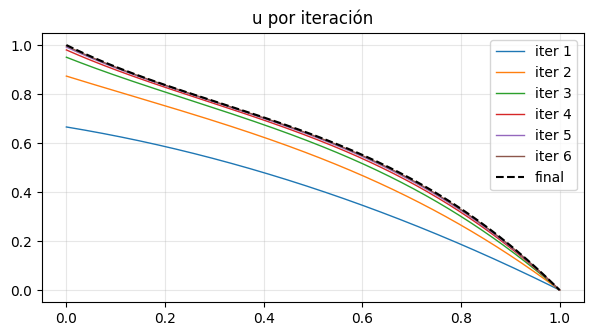

In [3]:
A, B, C, x0 = 1, 1, 4, 1.0
res = fbsm(lambda t, x, u: -0.5*x**2 + C*u,
           lambda t, x, u, l: -A + l*x,
           lambda t, x, l: C*l/(2*B),
           x0, lambda xT: np.zeros(1), 1.0, historia=True, tol=1e-6)
print('iteraciones:', res['iters'])
for i, uk in enumerate(res['hist'][:6]):
    plt.plot(res['t'], uk[:, 0], lw=1, label=f'iter {i+1}')
plt.plot(res['t'], res['u'][:, 0], 'k--', label='final'); plt.legend(); plt.title('u por iteración'); plt.show()

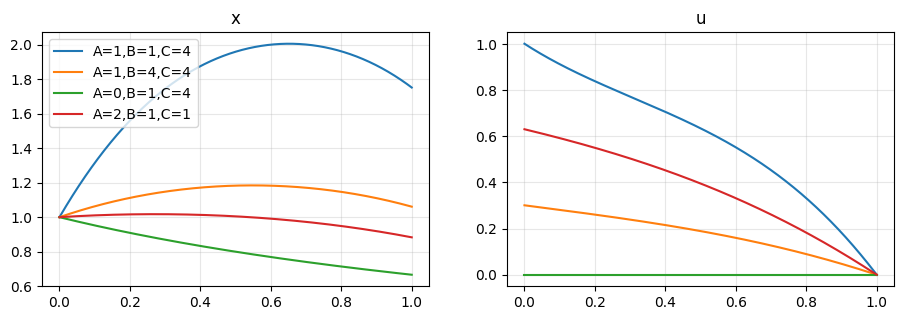

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
for (A, B, C) in [(1, 1, 4), (1, 4, 4), (0, 1, 4), (2, 1, 1)]:
    r = fbsm(lambda t, x, u: -0.5*x**2 + C*u, lambda t, x, u, l: -A + l*x,
             lambda t, x, l: C*l/(2*B), 1.0, lambda xT: np.zeros(1), 1.0)
    ax[0].plot(r['t'], r['x'][:, 0], label=f'A={A},B={B},C={C}'); ax[1].plot(r['t'], r['u'][:, 0])
ax[0].legend(); ax[0].set_title('x'); ax[1].set_title('u'); plt.show()

## 3. La relajación importa
Problema LQ de la Clase 2 (solución exacta conocida). Probamos distintos $\omega$.

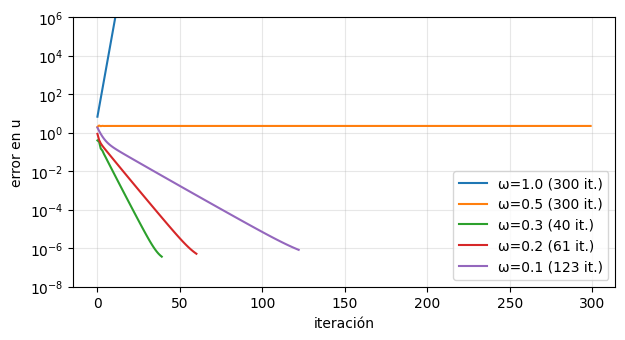

In [5]:
c = 3*np.exp(-4)/(3*np.exp(-4) + 1); d = 1/(3*np.exp(-4) + 1)
for omega in [1.0, 0.5, 0.3, 0.2, 0.1]:
    r = fbsm(lambda t, x, u: x + u, lambda t, x, u, l: 3*x - l, lambda t, x, l: l,
             1.0, lambda xT: np.zeros(1), 1.0, omega=omega, maxit=300, tol=1e-8, historia=True)
    ua = c*np.exp(2*r['t']) - 3*d*np.exp(-2*r['t'])
    errs = [np.abs(h[:, 0] - ua).max() for h in r['hist']]
    plt.semilogy(errs, label=f'ω={omega} ({r["iters"]} it.)')
plt.ylim(1e-8, 1e6); plt.xlabel('iteración'); plt.ylabel('error en u'); plt.legend(); plt.show()

## 4. Orden de convergencia en $N$

In [6]:
Ns = [25, 50, 100, 200, 400]; errs = []
for N in Ns:
    r = fbsm(lambda t, x, u: x + u, lambda t, x, u, l: 3*x - l, lambda t, x, l: l,
             1.0, lambda xT: np.zeros(1), 1.0, N=N, omega=0.3, tol=1e-12, maxit=500)
    ua = c*np.exp(2*r['t']) - 3*d*np.exp(-2*r['t'])
    errs.append(np.abs(r['u'][:, 0] - ua).max())
print('errores:', errs)
print('orden estimado:', np.polyfit(np.log(1/np.array(Ns)), np.log(errs), 1)[0])

errores: [np.float64(0.0004801753302021705), np.float64(0.00012000441841197862), np.float64(2.9998626417171437e-05), np.float64(7.499705338087637e-06), np.float64(1.8749305246146264e-06)]
orden estimado: 2.0001270474788955


## 5. Método de tiro
Para el Lab 1: incógnita $\lambda_0=\lambda(0)$, función de tiro $S(\lambda_0)=\lambda(1)$.

In [7]:
A, B, C = 1, 1, 4
def S(l0):
    s = solve_ivp(lambda t, y: [-0.5*y[0]**2 + C*C*y[1]/(2*B), -A + y[1]*y[0]], [0, 1], [1.0, l0],
                  rtol=1e-10, atol=1e-12)
    return s.y[1, -1]
l0 = brentq(S, 0.2, 0.8)
print('lambda(0) por tiro:', l0, '   lambda(0) por FBSM:', res['lam'][0, 0])
for l in [0.4, 0.5, 0.6, 0.8, 0.88]:
    print(f'S({l}) = {S(l):.4f}')

lambda(0) por tiro: 0.5008589766803931    lambda(0) por FBSM: 0.5008590555831685
S(0.4) = -0.5220
S(0.5) = -0.0074
S(0.6) = 1.5943
S(0.8) = 41.4215
S(0.88) = 633.0156


`solve_bvp` hace algo más robusto (colocación), equivalente a un tiro múltiple:

In [8]:
tb = np.linspace(0, 1, 30)
sb = solve_bvp(lambda t, y: np.vstack([-0.5*y[0]**2 + C*C*y[1]/(2*B), -A + y[1]*y[0]]),
               lambda ya, yb: np.array([ya[0] - 1, yb[1]]), tb, np.zeros((2, tb.size)))
print(sb.message, '  lambda(0) =', sb.sol(0)[1])

The algorithm converged to the desired accuracy.   lambda(0) = 0.5008575149224506


## 6. Método directo con adjunto discreto (= backprop)
Discretizamos con Euler y maximizamos $\mathcal J(u_0,\dots,u_{N-1})$ con L-BFGS-B. El gradiente se calcula con
$p_N=\phi'(x_N)$, $\partial\mathcal J/\partial u_k=h(L_u+p_{k+1}f_u)$, $p_k=p_{k+1}(1+hf_x)+hL_x$.

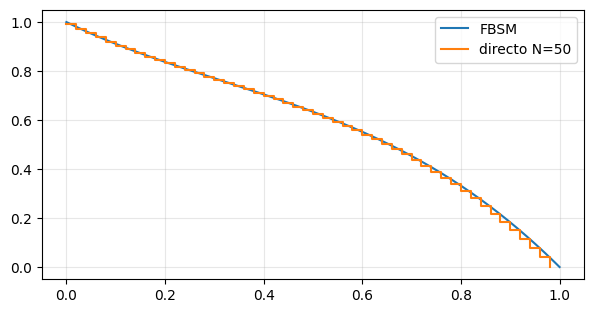

In [9]:
def directo(f, fx, fu, L, Lx, Lu, x0, T, N, cotas, phi=None, dphi=None, u0=None):
    h = T/N; t = np.linspace(0, T, N+1)
    def sim(u):
        x = np.zeros(N+1); x[0] = x0
        for k in range(N):
            x[k+1] = x[k] + h*f(t[k], x[k], u[k])
        return x
    def menosJ(u):
        x = sim(u)
        J = h*sum(L(t[k], x[k], u[k]) for k in range(N)) + (phi(x[N]) if phi else 0.0)
        p = dphi(x[N]) if dphi else 0.0; g = np.zeros(N)
        for k in range(N-1, -1, -1):
            g[k] = h*(Lu(t[k], x[k], u[k]) + p*fu(t[k], x[k], u[k]))
            p = p*(1 + h*fx(t[k], x[k], u[k])) + h*Lx(t[k], x[k], u[k])
        return -J, -g
    u0 = np.zeros(N) if u0 is None else u0
    r = minimize(menosJ, u0, jac=True, method='L-BFGS-B', bounds=[cotas]*N)
    return t, sim(r.x), r.x, -r.fun, menosJ

A, B, C = 1, 1, 4
t, x, u, J, menosJ = directo(lambda t, x, u: -0.5*x**2 + C*u, lambda t, x, u: -x, lambda t, x, u: C,
                             lambda t, x, u: A*x - B*u**2, lambda t, x, u: A, lambda t, x, u: -2*B*u,
                             1.0, 1.0, 50, (None, None))
plt.plot(res['t'], res['u'][:, 0], label='FBSM'); plt.step(t[:-1], u, where='post', label='directo N=50')
plt.legend(); plt.show()

Chequeo del gradiente discreto contra diferencias finitas:

In [10]:
u_test = np.random.default_rng(0).normal(size=50)
_, g = menosJ(u_test); e = np.zeros(50); e[17] = 1e-6
fd = (menosJ(u_test + e)[0] - menosJ(u_test - e)[0])/2e-6
print('adjunto discreto:', g[17], '  diferencias finitas:', fd)

adjunto discreto: -0.05609288672754288   diferencias finitas: -0.056092886668857034


## Para explorar
1. Bacterias con el método directo (incluye costo final: usar `phi` y `dphi`).
2. Tumor de la Clase 3 con el método directo para $N=20,40,80$: graficar $p_k$ y compararlo con $\lambda(t)=-e^{\alpha(T-t)}$.
3. ¿Qué método es más rápido para $N=1000$? Medir con `%timeit`.